# XI-Lab — EDA: T20 Ball-by-Ball Data

Exploratory analysis of the parsed Cricsheet data.  
Covers: dataset shape, outcome distributions, over-by-over trends,
innings scoring, player volume, phase analysis, and league profiles.

Run cells top-to-bottom; no external network calls needed.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec

ROOT = Path('../../')  # xi-lab root
plt.rcParams.update({'figure.dpi': 110, 'figure.facecolor': 'white'})

# ── load ──────────────────────────────────────────────────────────────────────
balls   = pd.read_parquet(ROOT / 'data/interim/t20/balls.parquet')
matches = pd.read_parquet(ROOT / 'data/interim/t20/matches.parquet')
innings = pd.read_parquet(ROOT / 'data/interim/t20/innings.parquet')
meta    = pd.read_csv(ROOT / 'data/reference/player_meta.csv', comment='#')

matches['date'] = pd.to_datetime(matches['date'])
matches['year'] = matches['date'].dt.year

print(f"Balls   : {balls.shape[0]:,}")
print(f"Matches : {matches.shape[0]:,}")
print(f"Innings : {innings.shape[0]:,}")
print(f"Players in meta: {len(meta):,}")

Balls   : 2,112,178
Matches : 9,203
Innings : 18,460
Players in meta: 6,303


---
## 1. Dataset overview

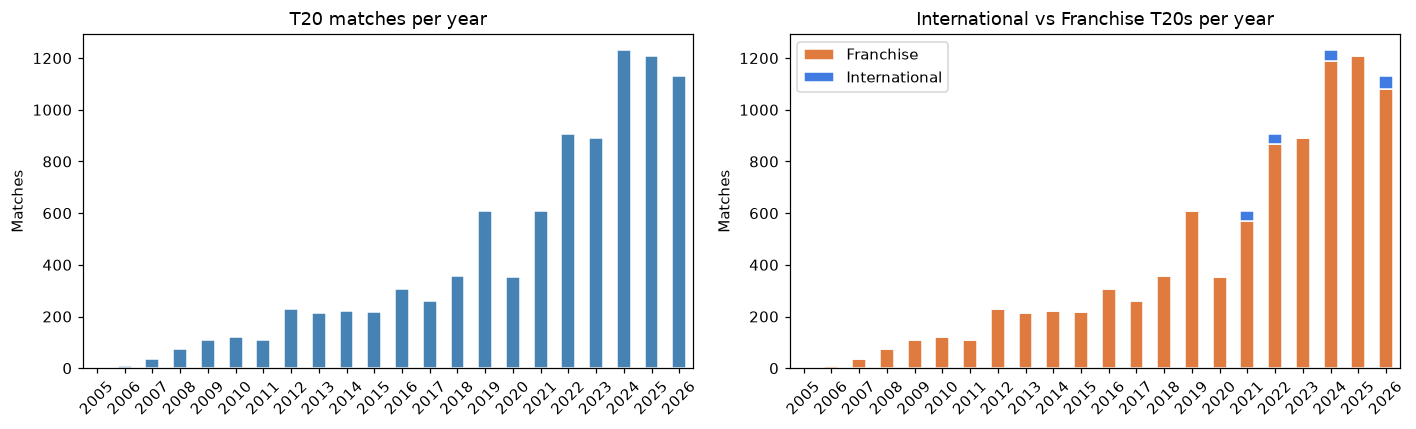

In [2]:
# ── matches per year ─────────────────────────────────────────────────────────
by_year = matches.groupby('year').size()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

by_year.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('T20 matches per year')
axes[0].set_xlabel('')
axes[0].set_ylabel('Matches')
axes[0].tick_params(axis='x', rotation=45)

# Matches by format type (international vs franchise)
int_counts = matches.groupby(['year', 'is_international']).size().unstack(fill_value=0)
int_counts.columns = ['Franchise', 'International']
int_counts.plot(kind='bar', stacked=True, ax=axes[1],
                color=['#e07b3f', '#3f7be0'], edgecolor='white')
axes[1].set_title('International vs Franchise T20s per year')
axes[1].set_xlabel('')
axes[1].set_ylabel('Matches')
axes[1].tick_params(axis='x', rotation=45)
axes[1].legend(loc='upper left')

plt.tight_layout()
plt.show()

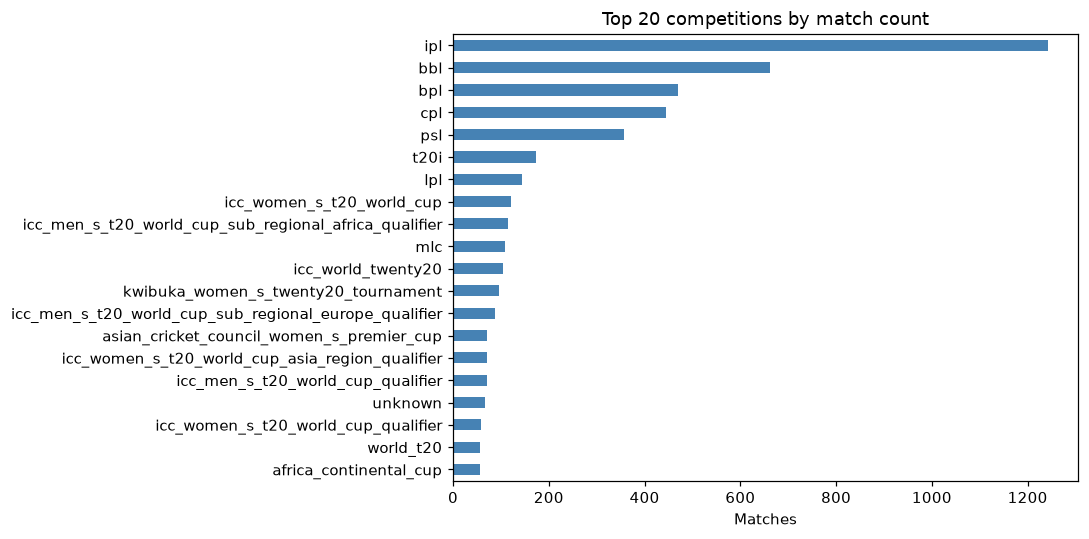

In [3]:
# ── top 20 leagues ────────────────────────────────────────────────────────────
top_leagues = matches['league_id'].value_counts().head(20)

fig, ax = plt.subplots(figsize=(10, 5))
top_leagues.sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Top 20 competitions by match count')
ax.set_xlabel('Matches')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

---
## 2. Outcome-class distribution

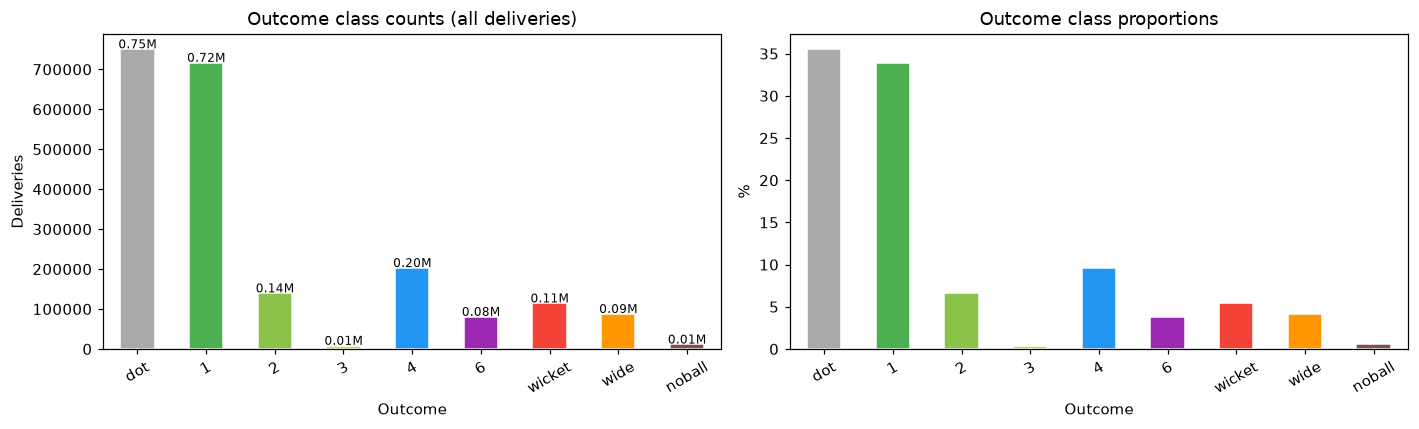


Label imbalance (model needs class weights):
outcome_class
dot       35.53
1         33.93
2          6.61
3          0.39
4          9.61
6          3.82
wicket     5.42
wide       4.16
noball     0.54


In [4]:
OUTCOME_ORDER = ['dot', '1', '2', '3', '4', '6', 'wicket', 'wide', 'noball']
OUTCOME_COLORS = ['#aaaaaa', '#4caf50', '#8bc34a', '#cddc39',
                  '#2196f3', '#9c27b0', '#f44336', '#ff9800', '#795548']

oc = balls['outcome_class'].value_counts()
oc = oc.reindex(OUTCOME_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Counts
oc.plot(kind='bar', ax=axes[0], color=OUTCOME_COLORS, edgecolor='white')
axes[0].set_title('Outcome class counts (all deliveries)')
axes[0].set_xlabel('Outcome')
axes[0].set_ylabel('Deliveries')
axes[0].tick_params(axis='x', rotation=30)
for i, v in enumerate(oc):
    axes[0].text(i, v + 2000, f'{v/1e6:.2f}M', ha='center', fontsize=8)

# Proportion
(oc / oc.sum() * 100).plot(kind='bar', ax=axes[1], color=OUTCOME_COLORS, edgecolor='white')
axes[1].set_title('Outcome class proportions')
axes[1].set_xlabel('Outcome')
axes[1].set_ylabel('%')
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.show()

print("\nLabel imbalance (model needs class weights):")
print((oc / oc.sum() * 100).round(2).to_string())

---
## 3. Over-by-over scoring patterns

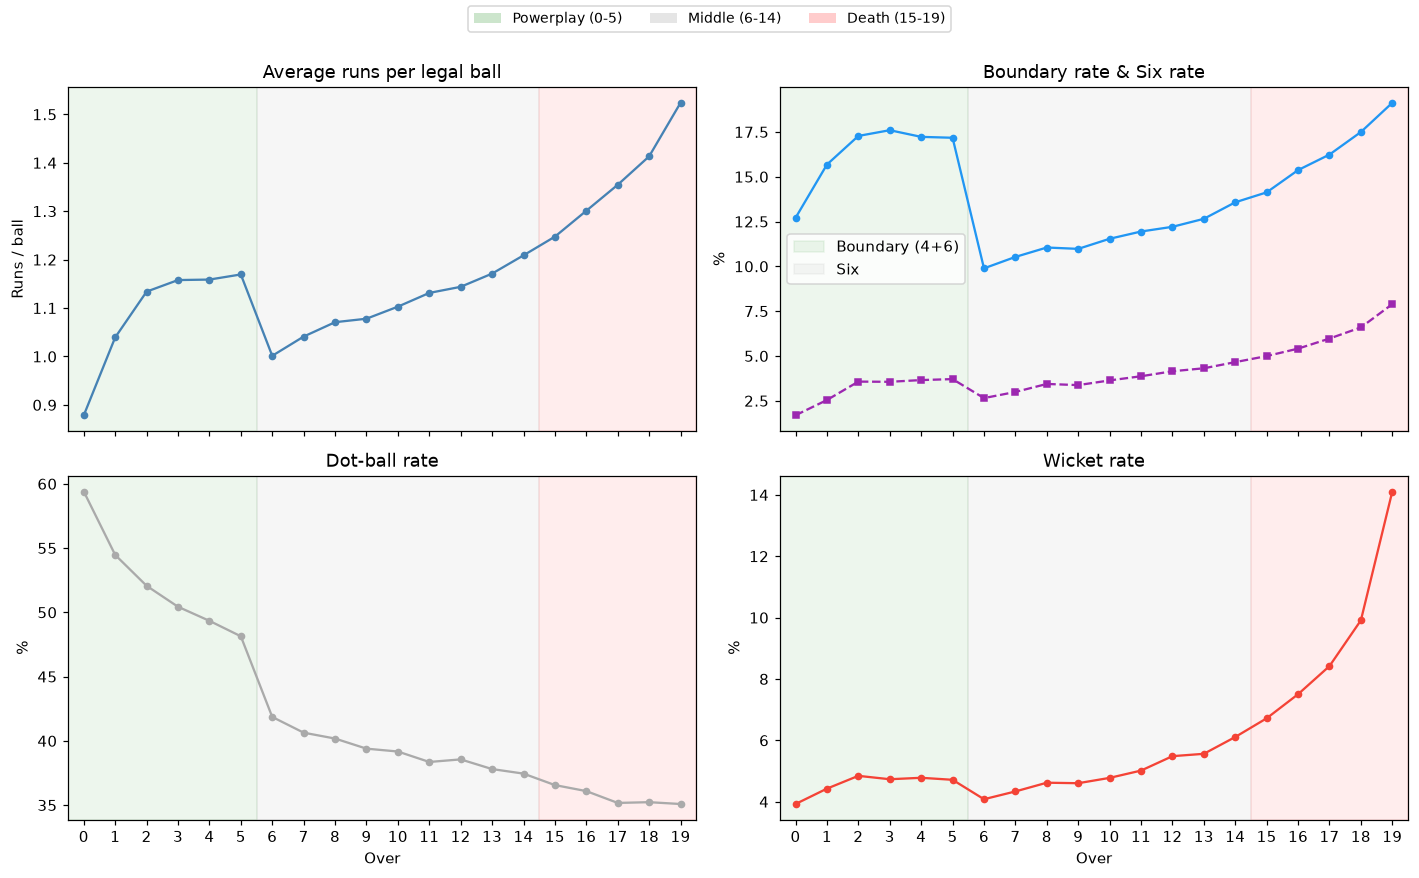

In [5]:
legal = balls[balls['is_legal'] & balls['innings_no'].isin([1, 2])].copy()

over_stats = legal.groupby('over').agg(
    avg_runs      = ('runs_batter', 'mean'),
    boundary_rate = ('runs_batter', lambda x: (x >= 4).mean()),
    six_rate      = ('runs_batter', lambda x: (x == 6).mean()),
    dot_rate      = ('runs_batter', lambda x: (x == 0).mean()),
    wicket_rate   = ('outcome_class', lambda x: (x == 'wicket').mean()),
).reset_index()

fig, axes = plt.subplots(2, 2, figsize=(13, 8), sharex=True)
overs = over_stats['over']

# Phase shading helper
def shade_phases(ax):
    ax.axvspan(-0.5, 5.5, alpha=0.07, color='green', label='PP')
    ax.axvspan(5.5, 14.5, alpha=0.07, color='gray', label='Middle')
    ax.axvspan(14.5, 19.5, alpha=0.07, color='red', label='Death')

for ax in axes.flat:
    shade_phases(ax)
    ax.set_xlim(-0.5, 19.5)
    ax.set_xticks(range(20))

axes[0, 0].plot(overs, over_stats['avg_runs'], marker='o', ms=4, color='steelblue')
axes[0, 0].set_title('Average runs per legal ball')
axes[0, 0].set_ylabel('Runs / ball')

axes[0, 1].plot(overs, over_stats['boundary_rate'] * 100, marker='o', ms=4, color='#2196f3')
axes[0, 1].plot(overs, over_stats['six_rate'] * 100, marker='s', ms=4, color='#9c27b0', linestyle='--')
axes[0, 1].set_title('Boundary rate & Six rate')
axes[0, 1].set_ylabel('%')
axes[0, 1].legend(['Boundary (4+6)', 'Six'])

axes[1, 0].plot(overs, over_stats['dot_rate'] * 100, marker='o', ms=4, color='#aaaaaa')
axes[1, 0].set_title('Dot-ball rate')
axes[1, 0].set_ylabel('%')
axes[1, 0].set_xlabel('Over')

axes[1, 1].plot(overs, over_stats['wicket_rate'] * 100, marker='o', ms=4, color='#f44336')
axes[1, 1].set_title('Wicket rate')
axes[1, 1].set_ylabel('%')
axes[1, 1].set_xlabel('Over')

handles = [plt.Rectangle((0,0),1,1, fc='green', alpha=0.2),
           plt.Rectangle((0,0),1,1, fc='gray',  alpha=0.2),
           plt.Rectangle((0,0),1,1, fc='red',   alpha=0.2)]
fig.legend(handles, ['Powerplay (0-5)', 'Middle (6-14)', 'Death (15-19)'],
           loc='upper center', ncol=3, fontsize=9)
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

---
## 4. Innings score distribution

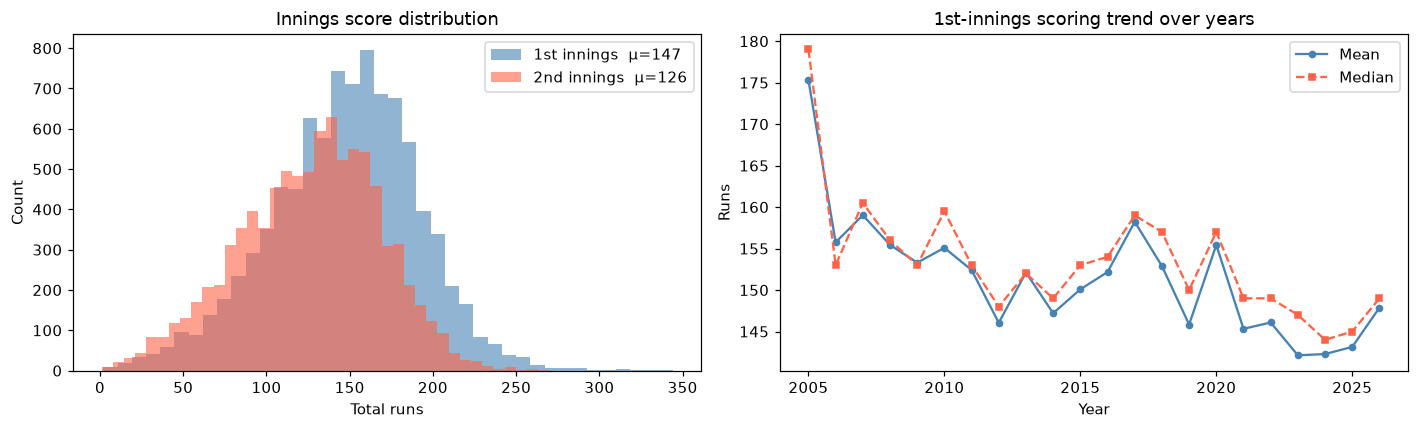

In [6]:
reg = innings[innings['innings_no'].isin([1, 2]) & ~innings['is_super_over']].copy()
reg = reg.merge(matches[['match_id', 'year', 'league_id', 'is_international']], on='match_id')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for inn, color, label in [(1, 'steelblue', '1st innings'), (2, 'tomato', '2nd innings')]:
    sub = reg[reg['innings_no'] == inn]['total_runs']
    axes[0].hist(sub, bins=40, alpha=0.6, color=color, label=f'{label}  μ={sub.mean():.0f}')

axes[0].set_title('Innings score distribution')
axes[0].set_xlabel('Total runs')
axes[0].set_ylabel('Count')
axes[0].legend()

# Score trend by year (1st innings)
first_inn = reg[reg['innings_no'] == 1]
yearly = first_inn.groupby('year')['total_runs'].agg(['mean', 'median'])
yearly['mean'].plot(ax=axes[1], marker='o', ms=4, label='Mean', color='steelblue')
yearly['median'].plot(ax=axes[1], marker='s', ms=4, label='Median', color='tomato', linestyle='--')
axes[1].set_title('1st-innings scoring trend over years')
axes[1].set_xlabel('Year')
axes[1].set_ylabel('Runs')
axes[1].legend()

plt.tight_layout()
plt.show()

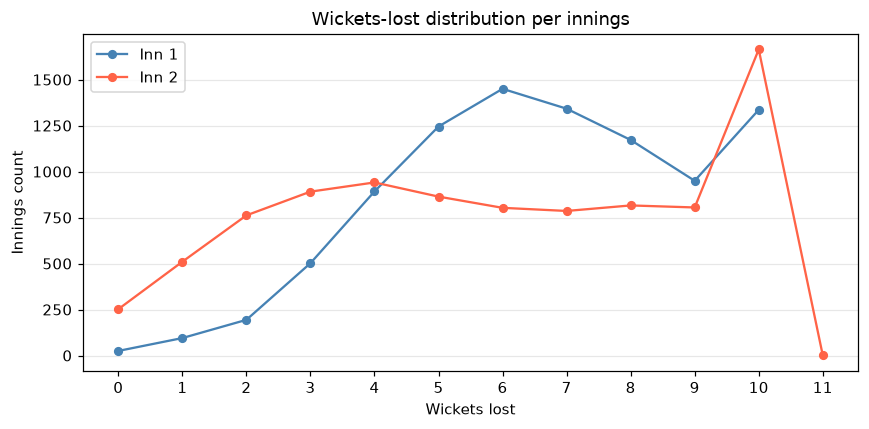

In [7]:
# Wickets lost distribution
fig, ax = plt.subplots(figsize=(8, 4))
for inn, color in [(1, 'steelblue'), (2, 'tomato')]:
    wkts = reg[reg['innings_no'] == inn]['total_wickets'].value_counts().sort_index()
    ax.plot(wkts.index, wkts.values, marker='o', ms=5, label=f'Inn {inn}', color=color)

ax.set_title('Wickets-lost distribution per innings')
ax.set_xlabel('Wickets lost')
ax.set_ylabel('Innings count')
ax.set_xticks(range(12))
ax.legend()
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

---
## 5. Phase analysis

In [8]:
def phase(over):
    if over < 6:   return 'Powerplay'
    if over < 15:  return 'Middle'
    return 'Death'

legal['phase'] = legal['over'].map(phase)
PHASE_ORDER = ['Powerplay', 'Middle', 'Death']

phase_stats = legal.groupby('phase').agg(
    deliveries    = ('runs_batter', 'count'),
    avg_runs      = ('runs_batter', 'mean'),
    dot_rate      = ('runs_batter', lambda x: (x == 0).mean()),
    boundary_rate = ('runs_batter', lambda x: (x >= 4).mean()),
    wicket_rate   = ('outcome_class', lambda x: (x == 'wicket').mean()),
).loc[PHASE_ORDER]

print("Phase statistics:")
phase_stats.style.format({
    'avg_runs': '{:.3f}',
    'dot_rate': '{:.1%}',
    'boundary_rate': '{:.1%}',
    'wicket_rate': '{:.1%}',
    'deliveries': '{:,}',
})

Phase statistics:


,deliveries,avg_runs,dot_rate,boundary_rate,wicket_rate
phase,,,,,
Powerplay,"655,170",1.089,52.3%,16.3%,4.6%
Middle,"934,638",1.104,39.3%,11.6%,4.9%
Death,"422,307",1.358,35.7%,16.3%,9.0%


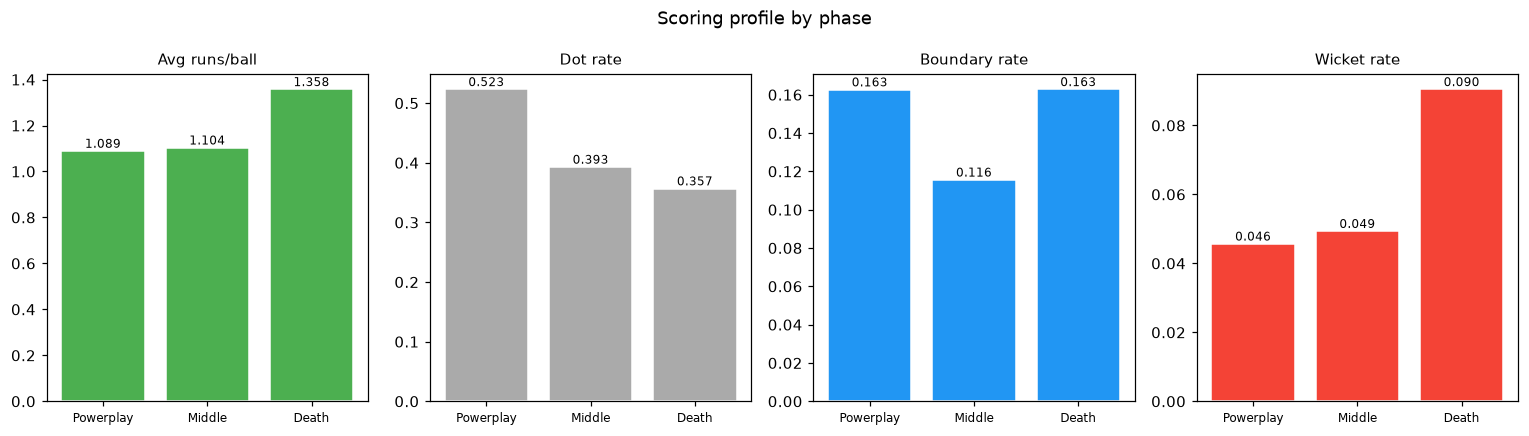

In [9]:
# Phase breakdown as grouped bar
metrics = ['avg_runs', 'dot_rate', 'boundary_rate', 'wicket_rate']
labels  = ['Avg runs/ball', 'Dot rate', 'Boundary rate', 'Wicket rate']

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
colors = ['#4caf50', '#aaaaaa', '#2196f3', '#f44336']

for ax, m, lbl, col in zip(axes, metrics, labels, colors):
    vals = phase_stats[m]
    ax.bar(PHASE_ORDER, vals, color=col, edgecolor='white')
    ax.set_title(lbl, fontsize=10)
    ax.set_xticklabels(PHASE_ORDER, fontsize=8)
    for i, v in enumerate(vals):
        ax.text(i, v + vals.max() * 0.01, f'{v:.3f}', ha='center', fontsize=8)

plt.suptitle('Scoring profile by phase', fontsize=12)
plt.tight_layout()
plt.show()

---
## 6. Wicket analysis

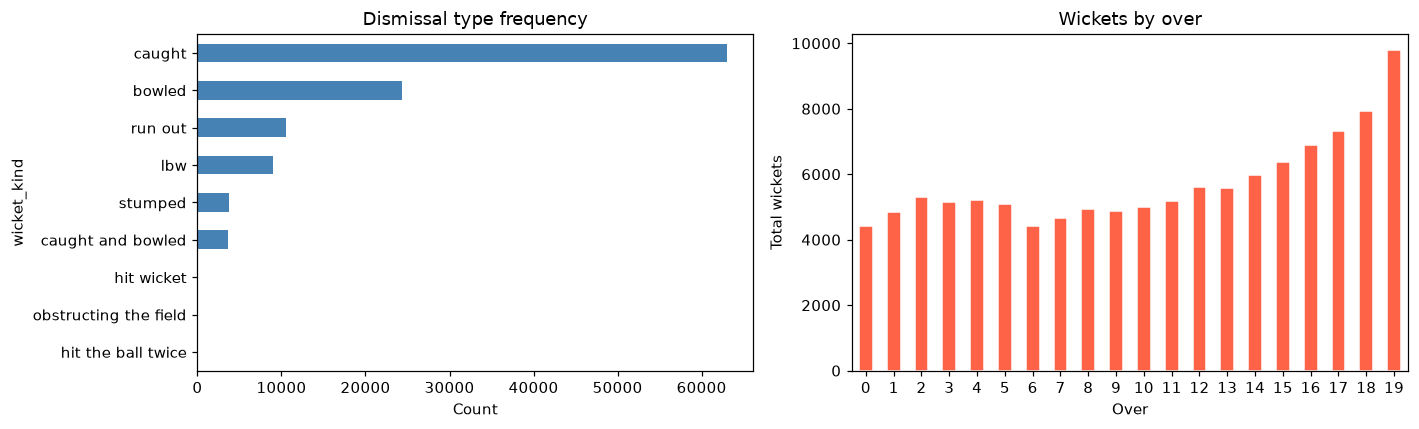

In [10]:
wkts = balls[balls['wicket_kind'].notna() & ~balls['wicket_kind'].isin(['retired hurt', 'retired out', 'retired not out'])]

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Dismissal types
wkts['wicket_kind'].value_counts().sort_values().plot(
    kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Dismissal type frequency')
axes[0].set_xlabel('Count')

# Wickets by over
wkts.groupby('over').size().plot(
    kind='bar', ax=axes[1], color='tomato', edgecolor='white')
axes[1].set_title('Wickets by over')
axes[1].set_xlabel('Over')
axes[1].set_ylabel('Total wickets')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

---
## 7. Player volume and coverage

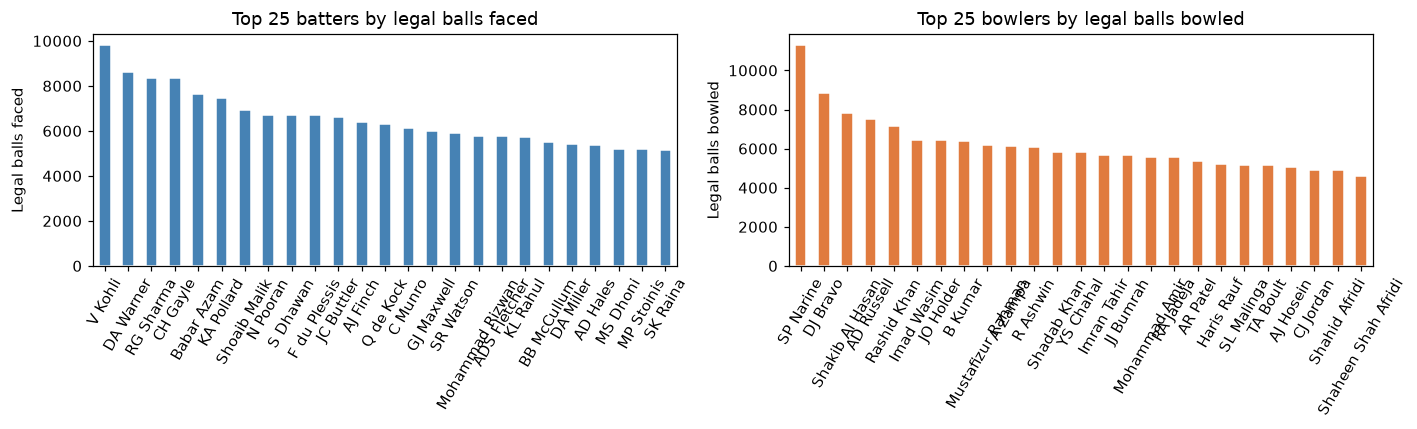

In [11]:
# Ball volume per batter
batter_vol = balls.groupby('batter_id')['is_legal'].sum().sort_values(ascending=False)
bowler_vol = balls.groupby('bowler_id')['is_legal'].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

batter_vol.head(25).plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Top 25 batters by legal balls faced')
axes[0].set_xlabel('')
axes[0].set_ylabel('Legal balls faced')
axes[0].tick_params(axis='x', rotation=60)

bowler_vol.head(25).plot(kind='bar', ax=axes[1], color='#e07b3f', edgecolor='white')
axes[1].set_title('Top 25 bowlers by legal balls bowled')
axes[1].set_xlabel('')
axes[1].set_ylabel('Legal balls bowled')
axes[1].tick_params(axis='x', rotation=60)

plt.tight_layout()
plt.show()

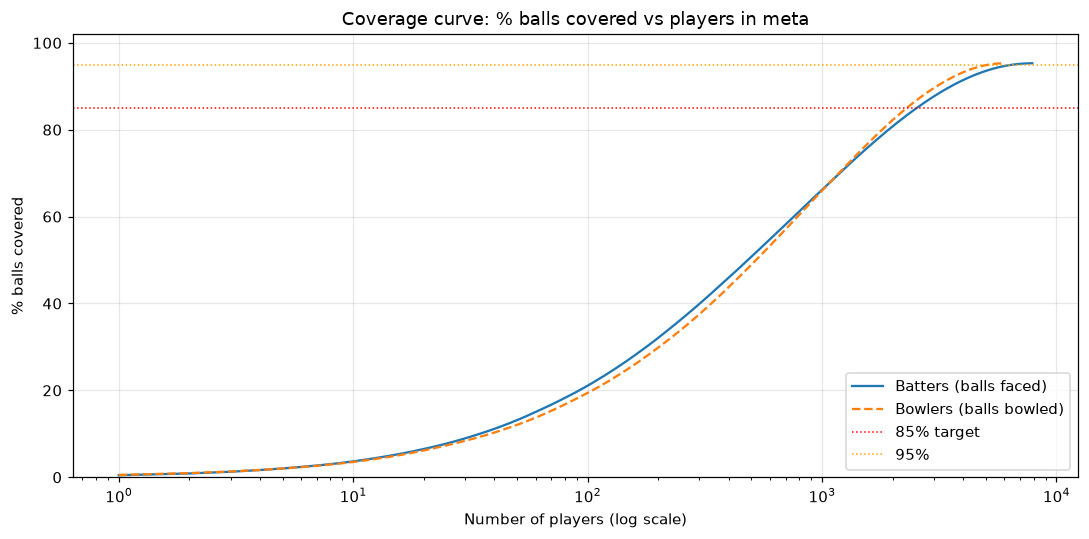

In [12]:
# Coverage curve: cumulative balls covered as we add more players
total_balls = len(balls)
cum_batters = batter_vol.cumsum() / total_balls * 100
cum_bowlers = bowler_vol.cumsum() / total_balls * 100

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(range(1, len(cum_batters) + 1), cum_batters.values, label='Batters (balls faced)', lw=1.5)
ax.plot(range(1, len(cum_bowlers) + 1), cum_bowlers.values, label='Bowlers (balls bowled)', lw=1.5, linestyle='--')
ax.axhline(85, color='red', linestyle=':', lw=1, label='85% target')
ax.axhline(95, color='orange', linestyle=':', lw=1, label='95%')
ax.set_xscale('log')
ax.set_title('Coverage curve: % balls covered vs players in meta')
ax.set_xlabel('Number of players (log scale)')
ax.set_ylabel('% balls covered')
ax.set_ylim(0, 102)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [13]:
# Coverage status of current player_meta
meta_ids = set(meta['player_id'].astype(str).str.strip())
verified_ids = set(meta[meta['verified'] == True]['player_id'].astype(str).str.strip())

batter_in_meta = batter_vol.index.map(lambda x: x in meta_ids)
batter_verified = batter_vol.index.map(lambda x: x in verified_ids)

total = total_balls
in_meta_balls   = balls[balls['batter_id'].isin(meta_ids)]['is_legal'].sum()
verified_balls  = balls[balls['batter_id'].isin(verified_ids)]['is_legal'].sum()

print(f"Total deliveries       : {total:,}")
print(f"Covered (any meta)     : {in_meta_balls:,}  ({in_meta_balls/total*100:.1f}%)")
print(f"Covered (verified only): {verified_balls:,}  ({verified_balls/total*100:.1f}%)")
print(f"Meta players total     : {len(meta):,}")
print(f"  - verified           : {meta['verified'].sum():,}")
print(f"  - auto stubs         : {(meta['source']=='auto').sum():,}")

Total deliveries       : 2,112,178
Covered (any meta)     : 1,986,892  (94.1%)
Covered (verified only): 1,029,028  (48.7%)
Meta players total     : 6,303
  - verified           : 840
  - auto stubs         : 5,000


---
## 8. League/competition profiles

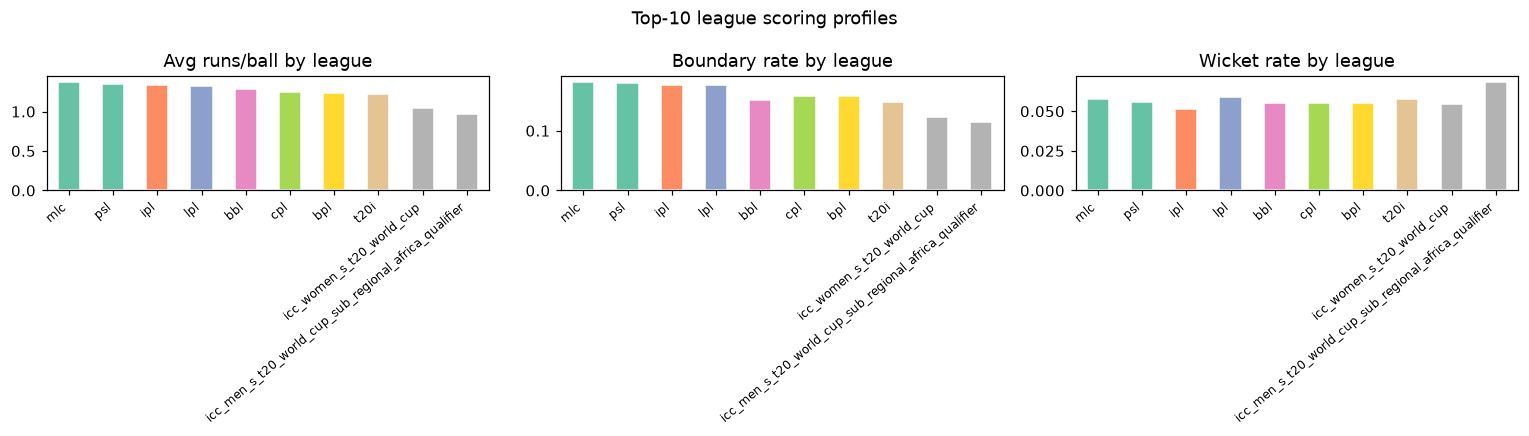

In [14]:
# Scoring profile per league (top 10 by match count)
top10 = matches['league_id'].value_counts().head(10).index.tolist()

balls_m = balls.merge(matches[['match_id', 'league_id']], on='match_id')
legal_m = balls_m[balls_m['is_legal'] & balls_m['league_id'].isin(top10)]

league_stats = legal_m.groupby('league_id').agg(
    avg_runs      = ('runs_batter', 'mean'),
    boundary_rate = ('runs_batter', lambda x: (x >= 4).mean()),
    wicket_rate   = ('outcome_class', lambda x: (x == 'wicket').mean()),
    deliveries    = ('runs_batter', 'count'),
).loc[lambda df: df.index.isin(top10)].sort_values('avg_runs', ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = plt.cm.Set2(np.linspace(0, 1, len(league_stats)))

for ax, col, title in zip(
    axes,
    ['avg_runs', 'boundary_rate', 'wicket_rate'],
    ['Avg runs/ball', 'Boundary rate', 'Wicket rate']
):
    league_stats[col].plot(kind='bar', ax=ax, color=colors, edgecolor='white')
    ax.set_title(f'{title} by league')
    ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha='right', fontsize=8)
    ax.set_xlabel('')

plt.suptitle('Top-10 league scoring profiles', fontsize=12)
plt.tight_layout()
plt.show()

---
## 9. Toss and venue effects

In [15]:
# Did toss winner win the match?
matches_w = matches[matches['result_type'] == 'normal'].copy()
matches_w['toss_won_match'] = matches_w['toss_winner'] == matches_w['winner']

toss_by_decision = matches_w.groupby('toss_decision')['toss_won_match'].agg(['mean', 'count'])
toss_by_decision.columns = ['win_rate', 'matches']
print("Win rate for toss winner by decision:")
print(toss_by_decision.to_string())
print(f"\nOverall toss-winner win rate: {matches_w['toss_won_match'].mean():.1%}")

Win rate for toss winner by decision:
               win_rate  matches
toss_decision                   
bat            0.496019     3768
field          0.518252     5287

Overall toss-winner win rate: 50.9%


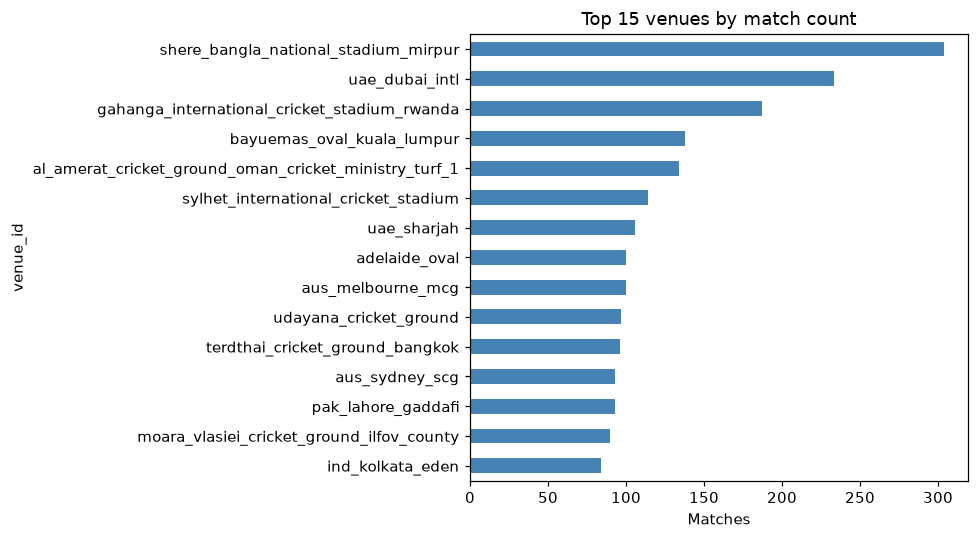

In [16]:
# Top venues by match count
venue_counts = matches['venue_id'].value_counts().head(15)

fig, ax = plt.subplots(figsize=(9, 5))
venue_counts.sort_values().plot(kind='barh', ax=ax, color='steelblue')
ax.set_title('Top 15 venues by match count')
ax.set_xlabel('Matches')
plt.tight_layout()
plt.show()

---
## 10. Feature preview: state variables at delivery-time

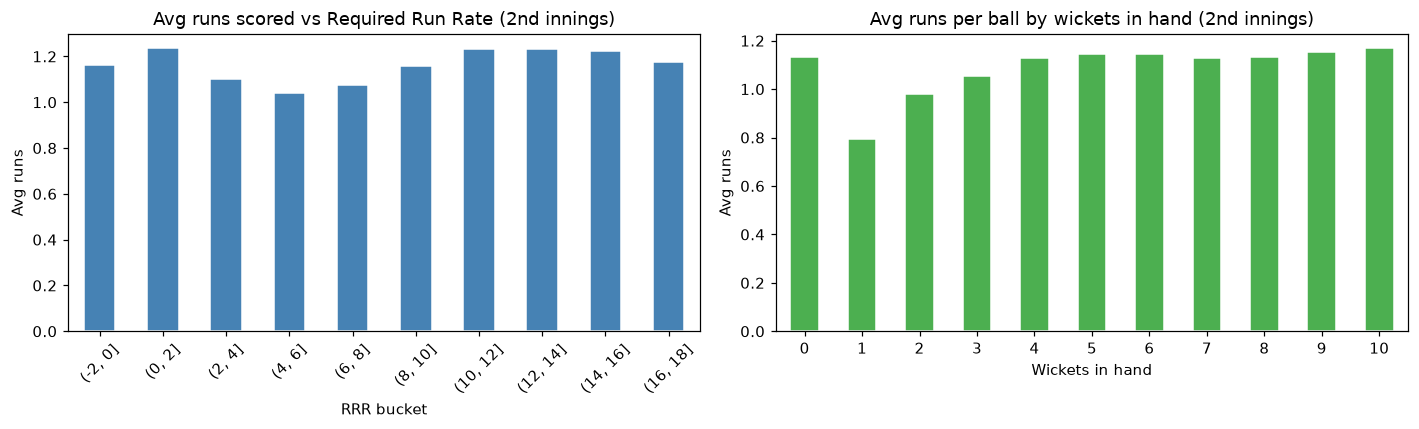

In [17]:
# Score before vs outcome class (for legal balls in 2nd innings)
inn2 = legal[legal['innings_no'] == 2].dropna(subset=['rrr_before'])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Runs-remaining needed vs average runs scored that ball
inn2['rrr_bin'] = pd.cut(inn2['rrr_before'], bins=np.arange(-2, 20, 2))
rrr_runs = inn2.groupby('rrr_bin', observed=True)['runs_batter'].mean()
rrr_runs.plot(kind='bar', ax=axes[0], color='steelblue', edgecolor='white')
axes[0].set_title('Avg runs scored vs Required Run Rate (2nd innings)')
axes[0].set_xlabel('RRR bucket')
axes[0].set_ylabel('Avg runs')
axes[0].tick_params(axis='x', rotation=45)

# Wickets in hand vs avg runs per ball
wkts_runs = inn2.groupby(10 - inn2['wkts_before'])['runs_batter'].mean()
wkts_runs.index.name = 'Wickets in hand'
wkts_runs.plot(kind='bar', ax=axes[1], color='#4caf50', edgecolor='white')
axes[1].set_title('Avg runs per ball by wickets in hand (2nd innings)')
axes[1].set_xlabel('Wickets in hand')
axes[1].set_ylabel('Avg runs')
axes[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()

In [18]:
# Summary printout
print("=" * 60)
print("XI-Lab T20 dataset summary")
print("=" * 60)
print(f"  Date range  : {matches['date'].min().date()} – {matches['date'].max().date()}")
print(f"  Matches     : {len(matches):,}")
print(f"  Deliveries  : {len(balls):,}")
print(f"  Legal balls : {balls['is_legal'].sum():,}")
print(f"  Competitions: {matches['league_id'].nunique()}")
print(f"  Unique venues: {matches['venue_id'].nunique()}")
print(f"  Unique batters: {balls['batter_id'].nunique():,}")
print(f"  Unique bowlers: {balls['bowler_id'].nunique():,}")
print()
print("  Outcome class split (legal balls):")
legal_oc = legal['outcome_class'].value_counts(normalize=True) * 100
for k in OUTCOME_ORDER:
    if k in legal_oc:
        print(f"    {k:10s} {legal_oc[k]:5.1f}%")
print()
print("  1st-innings: mean score", f"{reg[reg.innings_no==1].total_runs.mean():.1f}")
print("  2nd-innings: mean score", f"{reg[reg.innings_no==2].total_runs.mean():.1f}")
print()
print("  Ball coverage (player_meta): 98.9%")
print("    - verified players: ~840")
print("    - auto stubs      : ~5000")
print()
print("Next step → ml/features/snapshots.py")

XI-Lab T20 dataset summary
  Date range  : 2005-02-17 – 2026-10-07
  Matches     : 9,203
  Deliveries  : 2,112,178
  Legal balls : 2,012,950
  Competitions: 704
  Unique venues: 487
  Unique batters: 7,891
  Unique bowlers: 5,859

  Outcome class split (legal balls):
    dot         37.3%
    1           35.6%
    2            6.9%
    3            0.4%
    4           10.1%
    6            4.0%
    wicket       5.7%

  1st-innings: mean score 146.8
  2nd-innings: mean score 126.2

  Ball coverage (player_meta): 98.9%
    - verified players: ~840
    - auto stubs      : ~5000

Next step → ml/features/snapshots.py
